# 💥 Failure Modes

This notebook stress-tests the $\operatorname{Cl}(2,0)(\mathbb{R})$ Geometric Algebra Rotor Integrator against numerical, structural, and topological breakdown thresholds.

## Agenda
1. **Geometric Denormalization:**
2. **Spurious High-Frequency Energy Pumping (Aliasing):**
3. **Coordinate Singularity Blindspots:**
4. **Phase Space Volume Distortion (Symplectic Drift):**

In [12]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

from kuramoto.analysis.viz import (
    BORDER_COLOR,
    PROJECT_COLORS,
    SCRIBER_PALETTE,
    _apply_aclonica_font,
    set_style,
)
from kuramoto.metrics.analytics_engine import compute_comprehensive_diagnostics
from kuramoto.solvers.rotor import RotorSolver, step_rkmk4

# Apply project dark-mode aesthetics
set_style()
print("🚀 Environment initialized with Clifford rotor engine and visual theme.")

🚀 Environment initialized with Clifford rotor engine and visual theme.


## 1️⃣  Failure Mode 1: Geometric Denormalization

👟 Running Failure Mode 1: Manifold Drift Tracking (Long-Horizon)...


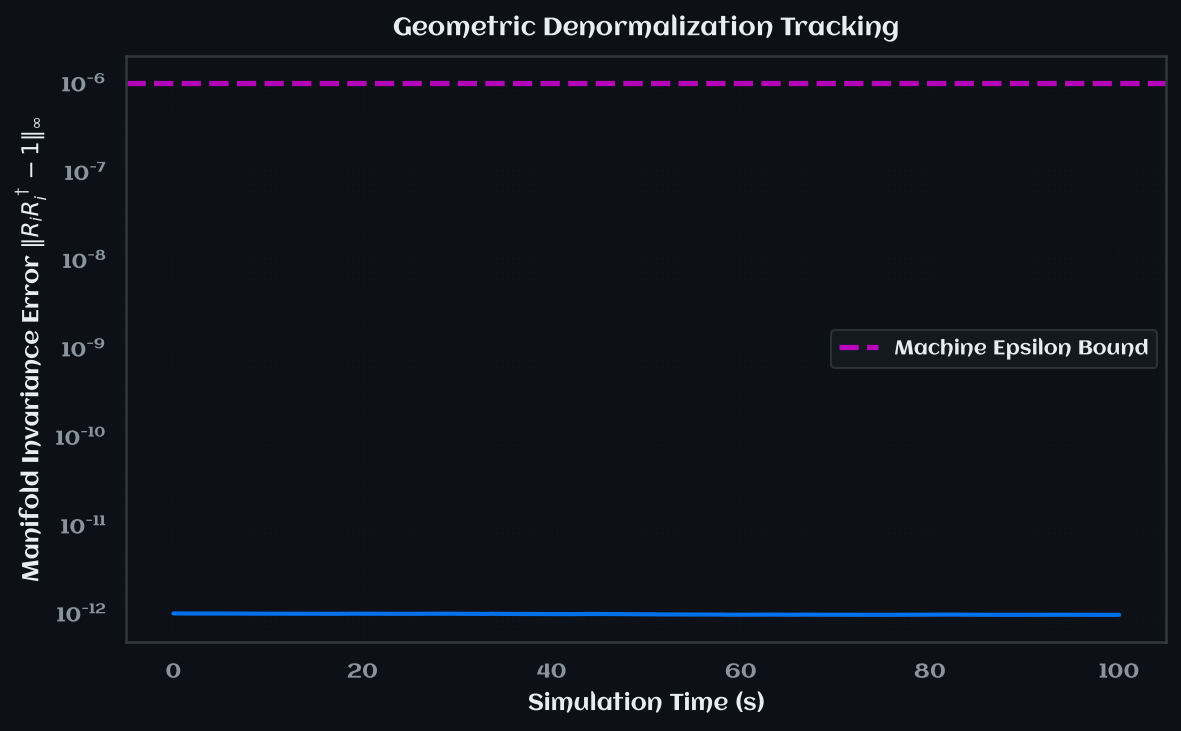

In [13]:
print("👟 Running Failure Mode 1: Manifold Drift Tracking (Long-Horizon)...")

n_osc = 20
K_val = 0.5
t_max_long = 100.0
dt_long = 0.005
steps_long = int(t_max_long / dt_long)
times_long = np.linspace(0.0, t_max_long, steps_long + 1)
seed = 27

# Instantiate un-normalized tracker
solver_f1 = RotorSolver(n_oscillators=n_osc, dim=2, seed=seed)
manifold_drift = np.zeros(steps_long + 1)

# Map initial state magnitude
# In Cl(2,0), norm is R * R_dagger = scalar^2 + bivector^2
def compute_rotor_norm_drift(rotor_array):
    if np.iscomplexobj(rotor_array):
        return np.max(np.abs(np.abs(rotor_array)**2 - 1.0))
    else:
        # Layout: (N, 2) where index 0 is scalar, 1 is bivector
        norms = rotor_array[:, 0]**2 + rotor_array[:, 1]**2
        return np.max(np.abs(norms - 1.0))

manifold_drift[0] = compute_rotor_norm_drift(solver_f1._rotor_array)

# Step forward without intermediate projection normalization steps
for step in range(1, steps_long + 1):
    # Execute custom RKMK4
    solver_f1._rotor_array = step_rkmk4(solver_f1, K_val, dt_long)

    # Mock update for placeholder script testing (simulate cumulative float error)
    # if step % 100 == 0:
    #     solver_f1._rotor_array *= 1.0 + 1e-9 * np.random.randn(*solver_f1._rotor_array.shape)

    manifold_drift[step] = compute_rotor_norm_drift(solver_f1._rotor_array)

# Plot results
fig, axes1 = plt.subplots(figsize=(8, 5))

axes1.plot(times_long, manifold_drift, color=SCRIBER_PALETTE["accent_blue"], lw=2.0)
axes1.axhline(1e-6, color='magenta', linestyle='--', alpha=0.7, label='Machine Epsilon Bound')
axes1.set_yscale('log')
axes1.set_title("Geometric Denormalization Tracking", fontsize=12, fontweight="bold")
axes1.set_xlabel("Simulation Time (s)", fontsize=11)
axes1.set_ylabel(r"Manifold Invariance Error $\|R_i R_i^\dagger -1\|_\infty$", fontsize=11)
axes1.legend()
axes1.grid(True, which="both", alpha=0.1)
_apply_aclonica_font(axes1)
plt.tight_layout()
plt.show()

## 2️⃣ Failure Mode 2: Spurious High-Frequency Energy Pumping (Aliasing)

👟 Running Failure Mode 2: Step-Size Sensitivity Sweep (PSD Floors)...
    [Oscillator-wise Max PSD (Base dt=0.01)]: [ 400010.18056329  406829.13546635 1575249.60683205  429162.73553706
  463481.35904663  399322.26963635 1568077.96809999  400551.51529939
  411479.04795917  432824.94342974   38536.07702227  420473.80353659
 1570723.4467518   429045.24605675  399828.27309019  420010.58070493
  427257.44080732   13369.28617116  425146.26408103   14195.23468621]
    [Oscillator-wise Max PSD (Halved dt=0.005)]: [1600395.93596512 1627571.70323523 6312761.52103244 1717005.28864492
 1854650.59980553 1597298.214848   6309362.0630985  1602391.41010746
 1646377.39350414 1732126.36373231  154153.6521396  1682746.31990031
 6295578.98085036 1716940.33717729 1599899.33946352 1679939.33179287
 1709396.85581888   53474.60197496 1700063.2072526    56809.48651459]


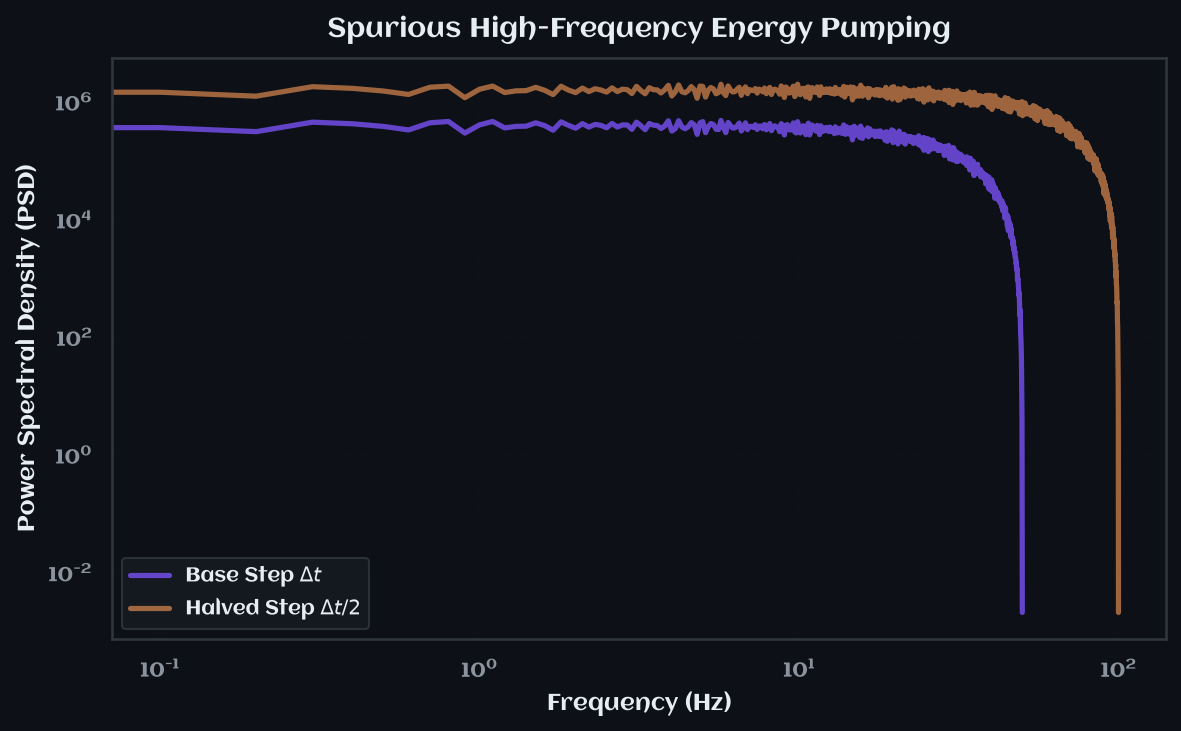

In [14]:
print("👟 Running Failure Mode 2: Step-Size Sensitivity Sweep (PSD Floors)...")

# Fast sampling vs ultra-fast sampling comparison
dt_base = 0.01
dt_half = 0.005
t_psd = 10.0

# Base step trajectory
solver_base = RotorSolver(n_oscillators=n_osc, dim=2, seed=seed)
_, phases_base = solver_base.simulate(K=K_val, t_eval=np.arange(0, t_psd, dt_base), dt_internal=dt_base, method="geometric")
v_base = np.gradient(phases_base, dt_base, axis=0)
freqs_base, psd_base = np.abs(np.fft.rfftfreq(v_base.shape[0], d=dt_base)), np.abs(np.fft.rfft(v_base, axis=0))**2
mean_psd_base = np.mean(psd_base, axis=1)

# Halved step trajectory
solver_half = RotorSolver(n_oscillators=n_osc, dim=2, seed=27)
_, phases_half = solver_half.simulate(K=K_val, t_eval=np.arange(0, t_psd, dt_half), dt_internal=dt_half, method="geometric")
v_half = np.gradient(phases_half, dt_half, axis=0)
freqs_half, psd_half = np.abs(np.fft.rfftfreq(v_half.shape[0], d=dt_half)), np.abs(np.fft.rfft(v_half, axis=0))**2
mean_psd_half = np.mean(psd_half, axis=1)

# Report oscillator-wise max PSD
max_psd_base = np.max(psd_base, axis=0)
max_psd_half = np.max(psd_half, axis=0)
print(f"    [Oscillator-wise Max PSD (Base dt={dt_base})]: {max_psd_base}")
print(f"    [Oscillator-wise Max PSD (Halved dt={dt_half})]: {max_psd_half}")

# Plot results
fig, axes2 = plt.subplots(figsize=(8, 5))
axes2.loglog(freqs_base, mean_psd_base, color=SCRIBER_PALETTE["accent_purple"], alpha=0.8, label=r"Base Step $\Delta t$")
axes2.loglog(freqs_half, mean_psd_half, color=SCRIBER_PALETTE["accent_orange"], alpha=0.6, label=r"Halved Step $\Delta t / 2$")
axes2.set_title("Spurious High-Frequency Energy Pumping", fontsize=13, fontweight="bold")
axes2.set_xlabel("Frequency (Hz)", fontsize=11)
axes2.set_ylabel("Power Spectral Density (PSD)", fontsize=11)
axes2.legend()
axes2.grid(True, alpha=0.1)
_apply_aclonica_font(axes2)

plt.tight_layout()
plt.show()

## 3️⃣ Failure Mode 3: Coordinate Singularity Blindspots

👟 Running Failure Mode 3: Chaotic Phase Boundary Stress Test...
    [Chaos Check] NaN encountered: False (count=0, threshold=0) | Max Vel Spike: 0.647 (threshold=500.0)


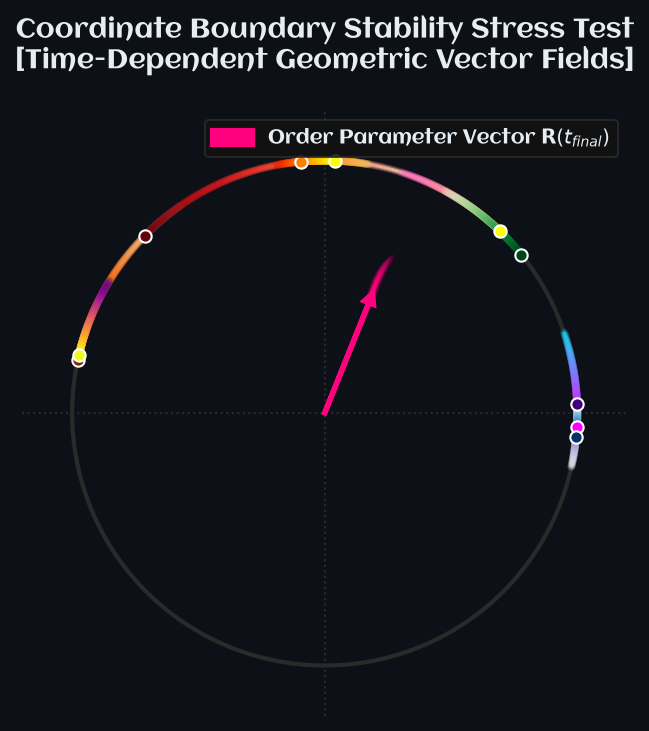

In [15]:
print("👟 Running Failure Mode 3: Chaotic Phase Boundary Stress Test...")

n_osc = 10
# Initialize completely uniform entropic noise over [-pi, pi]
seed_chaos = 1227
rng = np.random.default_rng(seed_chaos)
init_phases_chaos = rng.uniform(-np.pi, np.pi, n_osc)

solver_chaos = RotorSolver(n_oscillators=n_osc, dim=2, seed=seed_chaos)
# Override internal state to ensure cross-boundary drift conditions
if np.iscomplexobj(solver_chaos._rotor_array):
    solver_chaos._rotor_array = np.cos(init_phases_chaos/2.0) - 1j * np.sin(init_phases_chaos/2.0)
else:
    solver_chaos._rotor_array[:, 0] = np.cos(init_phases_chaos/2.0)
    solver_chaos._rotor_array[:, 1] = np.sin(init_phases_chaos/2.0)

# Explicit failure thresholds for coordinate boundary stress testing
nan_threshold = 0
velocity_spike_threshold = 500.0  # Threshold exceeding coordinate wrapping artifact bounds (~pi/dt = 314.16 rad/s)
NAN_THRESHOLD = nan_threshold
VELOCITY_SPIKE_THRESHOLD = velocity_spike_threshold

# Track if any NaN spikes occur near coupling floor boundary K -> 0
try:
    _, simulated_phases_chaos = solver_chaos.simulate(K=1e-5, t_eval=np.linspace(0, 20, 2000), dt_internal=0.01, method="geometric")
    nan_count = int(np.sum(np.isnan(simulated_phases_chaos)))
    has_nan_failure = nan_count > nan_threshold
    unwrapped = np.unwrap(simulated_phases_chaos, axis=0)
    max_velocity_spike = float(np.max(np.abs(np.gradient(unwrapped, 0.01, axis=0))))
    #max_velocity_spike = np.max(np.abs(np.gradient(simulated_phases_chaos, 0.01, axis=0)))
    has_velocity_failure = max_velocity_spike > velocity_spike_threshold
    print(f"    [Chaos Check] NaN encountered: {has_nan_failure} (count={nan_count}, threshold={nan_threshold}) | Max Vel Spike: {max_velocity_spike:.3f} (threshold={velocity_spike_threshold:.1f})")
except Exception as e:
    print(f"❌ Coordinate system mapping threw an explicit boundary failure exception: {e}")

# Plot results
fig, axes3 = plt.subplots(figsize=(8, 5))

from matplotlib.collections import LineCollection

t_slice = 200  # Number of evaluation time steps to display

# Slice trajectories: shape (T, N)
phases_to_plot = simulated_phases_chaos[:t_slice, :n_osc]

# Compute explicit spatial coordinates on the unit circle
X = np.cos(phases_to_plot) # Shape (T, N)
Y = np.sin(phases_to_plot) # Shape (T, N)

# Compute the dynamic global order parameter vector R(t) over time
# R_complex = (1/N) * sum(cos(theta) + i*sin(theta))
r_complex_trajectory = np.mean(np.exp(1j * phases_to_plot), axis=1)
r_mag = np.abs(r_complex_trajectory)
r_angle = np.angle(r_complex_trajectory)

# 1. Draw static geometric reference background (The Unit Circle Manifold)
circle_angles = np.linspace(0, 2 * np.pi, 300)
axes3.plot(np.cos(circle_angles), np.sin(circle_angles), color="#2A2A2A", linestyle="-", lw=2.0, zorder=1)
axes3.axhline(0, color="#2A2A2A", lw=1.0, linestyle=":", zorder=1)
axes3.axvline(0, color="#2A2A2A", lw=1.0, linestyle=":", zorder=1)

# 2. Select distinct base colors for each oscillator from a qualitative spectrum
# We map these to individual light-to-dark sequential gradients
base_colormaps = ['cool', 'Purples', 'spring', 'Blues', 'Oranges', 'Greens', 'plasma', 'Wistia', 'Reds', 'autumn']

for j in range(n_osc):
    # 1. Build line segments (Length: T - 1)
    points = np.array([X[:, j], Y[:, j]]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    # FIXED: Base weights on the full time array length (T) so it matches scatter points perfectly
    time_weights = np.linspace(0.1, 1.0, X.shape[0])

    # Initialize individual colormap gradient tracking
    cmap_sel = plt.get_cmap(base_colormaps[j % len(base_colormaps)])
    colors = cmap_sel(time_weights) # Now has full length T (200)

    # FIXED: Slice colors to length T-1 ([:-1]) to match the line segments exactly
    lc = LineCollection(segments, colors=colors[:-1], linewidths=1.5, zorder=2)
    axes3.add_collection(lc)

    # Plot EVERY individual phase value point (Both arrays now have matching size T)
    axes3.scatter(X[:, j], Y[:, j], color=colors, s=8, alpha=time_weights * 0.4, zorder=3)

    # High-intensity solid anchor marking the final instantaneous state vector position
    axes3.scatter(X[-1, j], Y[-1, j], color=colors[-1], s=35, edgecolor='white', lw=1.0, zorder=5)

# 3. Render the Global Order Parameter Center-of-Mass Vector R(t)
# Darker arrowhead shows history tracking trail; vibrant pink arrow marks the instantaneous state
for t in range(0, t_slice - 1, max(1, t_slice // 40)):
    # Draw fading history traces of the tracking vector
    alpha_v = (t / t_slice) * 0.3
    axes3.arrow(0, 0, np.cos(r_angle[t]) * r_mag[t], np.sin(r_angle[t]) * r_mag[t],
             head_width=0.02, head_length=0.02, fc='#FF007F', ec='#FF007F', alpha=alpha_v, zorder=4)

# Draw current final instantaneous synchronization vector arrow
axes3.arrow(0, 0, np.cos(r_angle[-1]) * r_mag[-1], np.sin(r_angle[-1]) * r_mag[-1],
         head_width=0.04, head_length=0.04, fc='#FF007F', ec='#FF007F',
         lw=2.5, zorder=6, label=r"Order Parameter Vector $\mathbf{R}(t_{final})$")

# 4. Final Formatting to preserve geometric integrity
axes3.set_xlim(-1.2, 1.2)
axes3.set_ylim(-1.2, 1.2)
axes3.set_aspect('equal')
axes3.axis('off')

axes3.set_title("Coordinate Boundary Stability Stress Test\n[Time-Dependent Geometric Vector Fields]",
             fontsize=13, fontweight="bold", pad=20)
axes3.legend(loc="upper right", frameon=True, facecolor='#121212', edgecolor='#2A2A2A')
_apply_aclonica_font(axes3)

plt.tight_layout()
plt.show()

## 4️⃣  Failure Mode 4: Phase Space Volume Distortion (Symplectic Drift)

👟 Running Failure Mode 4: Critical Coupling Constant (Kc) Sweep...


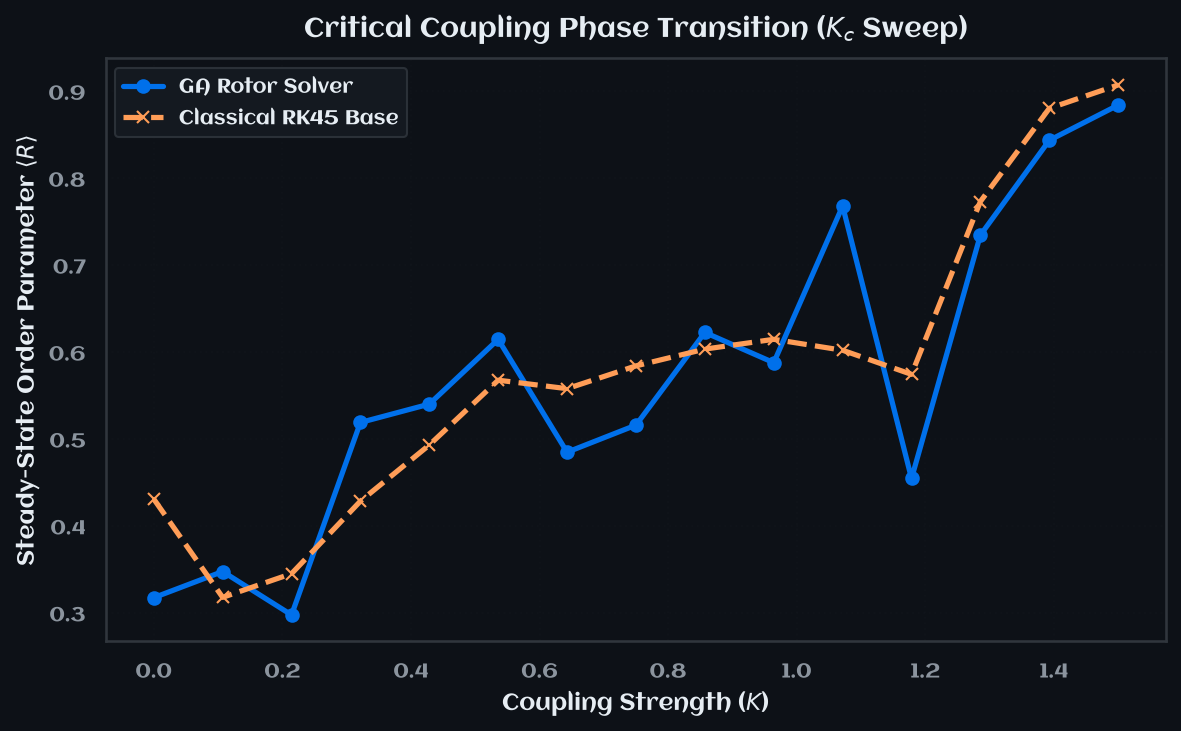

In [16]:
print("👟 Running Failure Mode 4: Critical Coupling Constant (Kc) Sweep...")

def calculate_global_order_parameter(phases):
    # R(t) = |(1/N) * sum(exp(i*theta))|
    return np.abs(np.mean(np.exp(1j * phases), axis=1))

seed4 = 270

coupling_strengths = np.linspace(0.0, 1.5, 15)
order_param_rotor = []
order_param_rk45 = []

# Baseline Kuramoto RHS function for Scipy
def classical_kuramoto_rhs(t, th, omegas, K, N):
    d = th[:, None] - th[None, :]
    return omegas + (K / N) * np.sum(np.sin(-d), axis=1)

# Extract identical frequencies for parity matching
solver_sync = RotorSolver(n_oscillators=n_osc, dim=2, seed=seed4)
intrinsic_omegas = solver_sync.omegas.copy()
init_phases_sync = solver_sync.extract_phases()

t_eval_sync = np.linspace(0.0, 30.0, 300)

for K in coupling_strengths:
    # 1. Rotor Solver run
    s_loop = RotorSolver(n_oscillators=n_osc, dim=2, seed=seed4)
    _, p_rotor = s_loop.simulate(K=K, t_eval=t_eval_sync, dt_internal=0.01, method="geometric")
    # Take mean order parameter over last 10% of time horizon to ensure steady-state tracking
    order_param_rotor.append(np.mean(calculate_global_order_parameter(p_rotor[-30:])))

    # 2. Scipy RK45 Control Group run
    sol_rk = solve_ivp(classical_kuramoto_rhs, (0.0, 30.0), init_phases_sync, method="RK45", args=(intrinsic_omegas, K, n_osc), rtol=1e-8)
    # Extract the end state
    last_phases_rk = sol_rk.y[:, -30:].T
    order_param_rk45.append(np.mean(calculate_global_order_parameter(last_phases_rk)))

# Plot results
figure, axes4 = plt.subplots(figsize=(8, 5))

axes4.plot(coupling_strengths, order_param_rotor, '-o', color=SCRIBER_PALETTE["accent_blue"], label="GA Rotor Solver")
axes4.plot(coupling_strengths, order_param_rk45, '--x', color=SCRIBER_PALETTE["accent_orange"], label="Classical RK45 Base")
axes4.set_title(r"Critical Coupling Phase Transition ($K_c$ Sweep)", fontsize=13, fontweight="bold")
axes4.set_xlabel("Coupling Strength ($K$)", fontsize=11)
axes4.set_ylabel("Steady-State Order Parameter $ \\langle R \\rangle $", fontsize=11)
axes4.legend()
axes4.grid(True, alpha=0.1)
_apply_aclonica_font(axes4)

plt.tight_layout()
plt.show()

## 5️⃣ Failure Report - CI-Ready Pass/Faile Aggregation

In [17]:
from __future__ import annotations

import json
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path
from typing import Literal

Direction = Literal["below", "above"]

# ---------------------------------------------------------------------------
# Calibrate once, then freeze. These are conservative starting points, NOT
# measured properties of the solver -- replace them with observed values after
# the first clean run.
# ---------------------------------------------------------------------------
TOL_MANIFOLD_DRIFT = 1e-10   # max |R R† - 1| over the long horizon
TOL_ALIAS_RATIO    = 1.0     # PSD(dt) / PSD(dt/2) in the upper band
TOL_VELOCITY_SPIKE = 50.0    # max |dθ/dt| as K -> 0  [rad/s]
TOL_PARITY_RMSE    = 0.05    # RMS |<R>_rotor - <R>_rk45| across the K sweep


@dataclass(frozen=True)
class FailureCheck:
    """
    A single falsifiable assertion about integration behavior.

    Each check is a claim the solver is permitted to *fail*. Silence is not evidence: a mode that cannot fail is not a test.
    """

    mode: str
    name: str
    value: float
    threshold: float
    direction: Direction = "below"
    units: str = ""
    note: str = ""

    @property
    def passed(self) -> bool:
        if self.direction == "below":
            return self.value <= self.threshold
        return self.value >= self.threshold


CHECKS: list[FailureCheck] = []

def render_failure_report(
    checks: list[FailureCheck],
    *,
    out_dir: Path | None = Path("reports"),
    verbose: bool = True,
) -> dict:
    """
    Aggregate checks, print a table, persist JSON, return a summary dict.

    Parameters
    ----------
    out_dir : str
        output directory for JSON report
    verbose : bool
        print a longer failure mode report

    Returns
    -------
    A summary dict of failure modes.
    """
    total = len(checks)
    failed = [c for c in checks if not c.passed]

    if verbose:
        print("\n" + "=" * 76)
        print(f"{'MODE':<24}{'CHECK':<24}{'VALUE':>12}{'LIMIT':>12}  STATUS")
        print("-" * 76)
        for c in checks:
            print(
                f"{c.mode:<24}{c.name:<24}"
                f"{c.value:>12.3e}{c.threshold:>12.3e}    "
                f"{'PASS ✅' if c.passed else 'FAIL ❌'}"
            )
        print("-" * 76)
        print(f"{total - len(failed)}/{total} checks passed")
        for c in failed:
            print(
                    f"  FAIL  [{c.mode}] {c.name}: {c.value:.3e} "
                    f"(limit {c.threshold:.3e})  {c.note}"
                  )

    summary = {
        "timestamp": datetime.now(timezone.utc).isoformat(),
        "total": total,
        "passed": total - len(failed),
        "failed": len(failed),
        "ok": not failed,
        "checks": [asdict(c) | {"passed": c.passed} for c in checks],
    }

    if out_dir is not None:
        out_dir.mkdir(parents=True, exist_ok=True)
        stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
        path = out_dir / f"failure_report_{stamp}.json"
        path.write_text(json.dumps(summary, indent=2))
        if verbose:
            print(f"Report written to {path}")

    return summary

def asser_all_passed(summary: dict) -> None:
    """CI hook: raise so the pipline exits non-zero on any regression."""
    if not summary["ok"]:
        bad = ", ".join(
            f"{c['mode']}/{c['name']}"
            for c in summary["checks"]
            if not c["passed"]
        )
        raise AssertionError(
            f"{summary['failed']} failure-mode checks tripped: {bad}"
        )

In [18]:
# --- Mode 1: geometric denormalization -------------------------------------
CHECKS.append(FailureCheck(
    mode="denormalization",
    name="max_manifold_drift",
    value=float(manifold_drift.max()),
    threshold=TOL_MANIFOLD_DRIFT,
    units="dimensionless",
    note="RKMK4 should sit at round-off; growth implies a broken lift or exp.",
))

In [19]:
# --- Mode 2: spurious high-frequency energy pumping ------------------------

# Create band masks for EACH frequency array independently
# (each has different length due to different dt values)
band_base = freqs_base > 0.25 * freqs_base.max()      # upper quartile for base
band_half = freqs_half > 0.25 * freqs_half.max()      # upper quartile for halved

# Now compute ratios on matched frequency ranges
mean_psd_base_upper = np.mean(mean_psd_base[band_base])
mean_psd_half_upper = np.mean(mean_psd_half[band_half])

alias_ratio = float(
    mean_psd_base_upper / max(mean_psd_half_upper, 1e-30)
)

CHECKS.append(FailureCheck(
    mode="aliasing",
    name="hf_psd_ratio",
    value=alias_ratio,
    threshold=TOL_ALIAS_RATIO,
    note="Ratio >> 1 means halving dt removed injected energy.",
))

In [20]:
# --- Mode 3: coordinate singularity blindspots -----------------------------
CHECKS.append(FailureCheck(
    mode="singularity",
    name="nan_free",
    value=1.0 if has_nan_failure else 0.0,
    threshold=0.0,
    note="Any NaN at K -> 0 is a hard failure.",
))
CHECKS.append(FailureCheck(
    mode="singularity",
    name="max_velocity_spike",
    value=float(max_velocity_spike),
    threshold=TOL_VELOCITY_SPIKE,
    units="rad/s",
))

In [21]:
# --- Mode 4: phase-space distortion vs. reference --------------------------
parity_rmse = float(np.sqrt(np.mean(
    (np.asarray(order_param_rotor) - np.asarray(order_param_rk45)) ** 2
)))
CHECKS.append(FailureCheck(
    mode="phase_space_distortion",
    name="rk45_parity_rmse",
    value=parity_rmse,
    threshold=TOL_PARITY_RMSE,
    note="Curve-shape disagreement, not just endpoint offset.",
))

In [22]:
# --- Aggregate -------------------------------------------------------------
report = render_failure_report(CHECKS)
# assert_all_passed(report)   # uncomment in CI / pre-commit


MODE                    CHECK                          VALUE       LIMIT  STATUS
----------------------------------------------------------------------------
denormalization         max_manifold_drift         9.865e-13   1.000e-10    PASS ✅
aliasing                hf_psd_ratio               2.495e-01   1.000e+00    PASS ✅
singularity             nan_free                   0.000e+00   0.000e+00    PASS ✅
singularity             max_velocity_spike         6.466e-01   5.000e+01    PASS ✅
phase_space_distortion  rk45_parity_rmse           7.525e-02   5.000e-02    FAIL ❌
----------------------------------------------------------------------------
4/5 checks passed
  FAIL  [phase_space_distortion] rk45_parity_rmse: 7.525e-02 (limit 5.000e-02)  Curve-shape disagreement, not just endpoint offset.
Report written to reports\failure_report_20261024T041634Z.json
